In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import requests
from io import BytesIO
from PIL import Image
from torchvision import transforms
from diffusers import AutoencoderKL

plt.style.use("bmh")

/Users/prakashjay/Downloads/GRN_blog/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Loading a COCO Image

COCO (Common Objects in Context) hosts ~330 k images at `images.cocodataset.org`. Each image has a zero-padded 12-digit ID. We grab one directly over HTTP — no need to download the full dataset.

In [2]:
coco_url = "http://images.cocodataset.org/val2017/000000039769.jpg"
response = requests.get(coco_url)
image = Image.open(BytesIO(response.content)).convert("RGB")
print(f"PIL image — size: {image.size}, mode: {image.mode}")

PIL image — size: (640, 480), mode: RGB


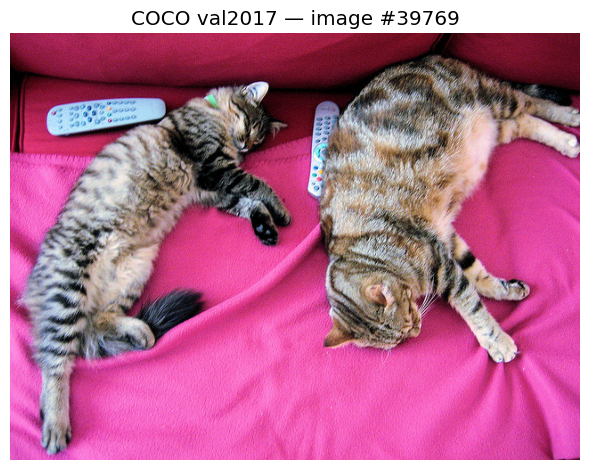

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(image)
ax.set(title="COCO val2017 — image #39769")
ax.axis("off")
plt.tight_layout()
plt.show()

Two cats on a sofa — a classic COCO scene. The image is 640 × 480 in RGB; the VAE expects 512 × 512, so we'll resize in the preprocessing step.

In [4]:
def load_coco_image(url: str) -> Image.Image:
    r = requests.get(url)
    r.raise_for_status()
    return Image.open(BytesIO(r.content)).convert("RGB")

## The Stable Diffusion VAE

The VAE used by SD 1.x compresses a 512 × 512 RGB image (3 channels) into a 64 × 64 latent grid with **4 channels** — an 8× spatial downscale. `sd-vae-ft-mse` is a fine-tuned version of the original SD 1.4 VAE with improved reconstruction quality.

The `scaling_factor` is a normalisation constant (~0.18) applied to the latents before diffusion, keeping their variance close to that of the noise schedule.

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").eval().to(device)
print(f"Device         : {device}")
print(f"Scaling factor : {vae.config.scaling_factor}")
print(f"Latent channels: {vae.config.latent_channels}")

/Users/prakashjay/Downloads/GRN_blog/.venv/lib/python3.13/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Device         : cpu
Scaling factor : 0.18215
Latent channels: 4


Device and scaling factor are confirmed — wrap the load logic into a reusable function.

In [6]:
def load_vae(model_id: str = "stabilityai/sd-vae-ft-mse") -> tuple[AutoencoderKL, str]:
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    model = AutoencoderKL.from_pretrained(model_id).eval().to(dev)
    return model, dev

## Preprocessing the Image

The VAE expects pixels normalised to **[−1, 1]** (not the usual ImageNet [0, 1] or [0, 255]). We resize to 512 × 512, convert to a float tensor, then apply `Normalize(mean=0.5, std=0.5)` per channel, which maps `[0, 1] → [−1, 1]`.

In [7]:
size = 512
transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])
tensor = transform(image).unsqueeze(0).to(device)  # (1, 3, 512, 512)
print(f"Tensor shape : {tuple(tensor.shape)}")
print(f"Value range  : [{tensor.min():.3f}, {tensor.max():.3f}]")

Tensor shape : (1, 3, 512, 512)
Value range  : [-1.000, 1.000]


The range `[-1.000, 1.000]` confirms the mapping. Wrap into `preprocess_image` for downstream use.

In [8]:
def preprocess_image(img: Image.Image, size: int = 512, device: str = "cpu") -> torch.Tensor:
    t = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
    ])
    return t(img).unsqueeze(0).to(device)

## Encoding to Latent Space

The encoder maps the image to a Gaussian distribution `q(z|x)` parameterised by a mean and log-variance. Calling `.sample()` on `latent_dist` draws one latent `z` from that distribution. In inference you can also use `.mode()` (the mean) for a deterministic result with slightly sharper reconstructions.

In [23]:
scaling_factor = vae.config.scaling_factor
print(f"Scaling factor: {scaling_factor}")
with torch.no_grad():
    dist = vae.encode(tensor).latent_dist
    latents = dist.sample()   # (1, 4, 64, 64)
    latents = latents * scaling_factor

print(f"Latent shape  : {tuple(latents.shape)}")
print(f"Mean          : {latents.mean().item():.4f}")
print(f"Std           : {latents.std().item():.4f}")
print(f"Min / Max     : {latents.min().item():.4f}  /  {latents.max().item():.4f}")

Scaling factor: 0.18215
Latent shape  : (1, 4, 64, 64)
Mean          : -0.3653
Std           : 0.8115
Min / Max     : -5.4181  /  3.0789


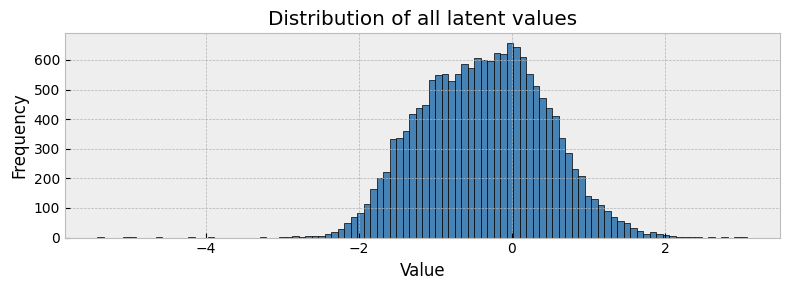

In [24]:
# Per-channel breakdown so we can see how each latent channel differs
ch_latents = latents.squeeze().cpu().numpy()  # (4, 64, 64)
flat_all   = ch_latents.flatten()

fig, ax = plt.subplots(1, 1, figsize=(8, 3))
ax.hist(flat_all, bins=100, color="steelblue", edgecolor="black")
ax.set(title="Distribution of all latent values", xlabel="Value", ylabel="Frequency")
plt.tight_layout()
plt.show()

Each channel shows a roughly Gaussian bell curve, which is exactly what the VAE regularisation term (KL divergence toward `N(0,1)`) encourages. The means cluster near zero but aren't identical — each channel has learned to encode different semantic content (colour, texture, luminance, edges). Channels with higher variance carry stronger signal from the image; the tighter ones are more regularised toward the prior.

In [26]:
def encode_image(img: Image.Image, vae: AutoencoderKL, device: str, size: int = 512) -> torch.Tensor:
    """Returns raw latents (1, 4, H/8, W/8). Divide by vae.config.scaling_factor before diffusion."""
    x = preprocess_image(img, size=size, device=device)
    with torch.no_grad():
        x = vae.encode(x).latent_dist.sample() * vae.config.scaling_factor
        return x


img2 = load_coco_image(coco_url)
z    = encode_image(img2, vae, device)
print(f"Shape: {tuple(z.shape)}  |  mean={z.mean():.4f}  std={z.std():.4f}")

Shape: (1, 4, 64, 64)  |  mean=-0.3653  std=0.8115


## HBQ — Hierarchical Binary Quantization

Stable Diffusion latents are continuous floats — feeding them to a language model requires discrete tokens. Standard vector quantization (VQ) makes one coarse codebook lookup and commits to that error permanently. HBQ instead asks a cascade of binary *higher-or-lower* questions: each round halves the remaining uncertainty, so after $M$ rounds the error is bounded by $2^{-M}$ — exponentially shrinking.

We start with a 4×4 toy tensor, trace every step by hand, then apply the full pipeline to real SD-VAE latents.

## Step 0 — Continuous Latents

A VAE encoder outputs unbounded real-valued floats for each spatial position. We simulate this with a 4×4 tensor — the same shape problem that a real encoder produces, just smaller so we can inspect every value.

In [29]:
F = torch.randn(4, 4) * 2.5   # unbounded: values can be anywhere
print("Raw encoder output:\n", F.round(decimals=3))
print(f"\nRange: [{F.min():.3f}, {F.max():.3f}]")

Raw encoder output:
 tensor([[-0.9250,  3.6210, -3.8190, -5.8330],
        [ 0.4280,  0.7290,  3.1810,  0.9900],
        [-3.2600, -1.3810,  2.6890, -1.1060],
        [ 0.2370,  1.7430,  0.1080,  2.3330]])

Range: [-5.833, 3.621]


The range spans roughly $(-6, 4)$ — unbounded. Binary bisection needs a fixed domain to split, which Step 1 solves with `tanh`.

## Step 1 — Bounding the Range with tanh

Binary bisection needs a *known bounded domain* to split. The GRN encoder applies `tanh()` as its final operation, squishing every float into `(-1, 1)`. tanh is monotonic — it preserves ordering — so no information is destroyed, just the scale changes.

In [30]:
F_bounded = torch.tanh(F)
print("After tanh:\n", F_bounded.round(decimals=3))
print(f"\nRange: [{F_bounded.min():.3f}, {F_bounded.max():.3f}]")

After tanh:
 tensor([[-0.7280,  0.9990, -0.9990, -1.0000],
        [ 0.4030,  0.6220,  0.9970,  0.7570],
        [-0.9970, -0.8810,  0.9910, -0.8020],
        [ 0.2320,  0.9410,  0.1070,  0.9810]])

Range: [-1.000, 0.999]


Large outliers are pulled toward ±1; interior values change little. The key guarantee: every element is now in `(-1, 1)`, giving bisection a clean domain to work with.

In [31]:
def bound_latents(x: torch.Tensor) -> torch.Tensor:
    return torch.tanh(x)

## Step 2 — One Binary Split

Start with center $c_0 = 0$ — the midpoint of $(-1, 1)$. At each round $i$, ask: *Is $F > c_i$?* That answer is one bit. Then move the center to the midpoint of whichever half $F$ landed in.

**Center update** (accumulates all prior bits):

$$c_i = \sum_{j=1}^{i-1} \frac{\delta[q_j]}{2^j}$$

**Bit assignment:**

$$q_i = \begin{cases} 0 & \text{if } F \leq c_i, \\ 1 & \text{if } F > c_i. \end{cases}$$

where $\delta[q] = 2q - 1 \in \{-1, +1\}$. Below we trace the first two rounds on our toy tensor.

In [38]:
center=0
m=0
q1 = (F_bounded > center).long()
delta = torch.where(q1>=1, 1, -1)
new_center = center+delta*((0.5)**(m+1))
new_center 

tensor([[-0.5000,  0.5000, -0.5000, -0.5000],
        [ 0.5000,  0.5000,  0.5000,  0.5000],
        [-0.5000, -0.5000,  0.5000, -0.5000],
        [ 0.5000,  0.5000,  0.5000,  0.5000]])

Round 0: center starts at 0. Each element moves to $\pm 0.5$ depending on which side of 0 it fell.

In [40]:
m = 1
q2 = (F_bounded > new_center).long()
delta = torch.where(q2>=1, 1, -1)
new_center_2 = new_center+delta*((0.5)**(m+1))
new_center_2


tensor([[-0.7500,  0.7500, -0.7500, -0.7500],
        [ 0.2500,  0.7500,  0.7500,  0.7500],
        [-0.7500, -0.7500,  0.7500, -0.7500],
        [ 0.2500,  0.7500,  0.2500,  0.7500]])

Round 1: centers move to $\pm 0.75$ or $\pm 0.25$ — the next binary subdivision. This pattern repeats for $M$ rounds, storing bits $q_1, q_2, \ldots, q_M$. After all rounds the running center equals the quantized approximation $\hat{F}$.

In [41]:
def hbq_encode(x: torch.Tensor, M: int = 4) -> torch.Tensor:
    """
    x      : any shape, values in (-1, 1)
    returns: bits tensor of shape (*x.shape, M), int8, values {0, 1}
    """
    center = torch.zeros_like(x)
    bits   = []
    for m in range(M):
        q      = (x > center).to(torch.int8)
        delta  = q.float() * 2 - 1          # 0 → -1,  1 → +1
        center = center + delta * (0.5 ** (m + 1))
        bits.append(q)
    return torch.stack(bits, dim=-1)         # (..., M)

In [42]:
bits = hbq_encode(F_bounded, M=4)
print("HBQ bits:\n", bits)

HBQ bits:
 tensor([[[0, 0, 1, 0],
         [1, 1, 1, 1],
         [0, 0, 0, 0],
         [0, 0, 0, 0]],

        [[1, 0, 1, 1],
         [1, 1, 0, 0],
         [1, 1, 1, 1],
         [1, 1, 1, 0]],

        [[0, 0, 0, 0],
         [0, 0, 0, 0],
         [1, 1, 1, 1],
         [0, 0, 0, 1]],

        [[1, 0, 0, 1],
         [1, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 1, 1, 1]]], dtype=torch.int8)


## Step 3 — Reconstruction from Bits

Decoding is pure arithmetic — no codebook lookup. Each bit contributes $\pm 2^{-\text{round}}$: bit=1 adds the positive step, bit=0 subtracts it. Summing all $M$ contributions gives $\hat{F}$:

$$\hat{F} = \delta[q_1] \cdot 2^{-1} + \delta[q_2] \cdot 2^{-2} + \cdots + \delta[q_M] \cdot 2^{-M}$$

The maximum possible error after $M$ bits is $2^{-(M+1)}$ — it halves with each additional bit.

Verify the formula by hand on element `[0, 0]` before wrapping into a function.

In [48]:
# Reconstruct element (0, 0) from its 4 bits — applying the formula above
x_hat_00 = 0.0
for m in range(bits.shape[-1]):
    d = float(bits[0, 0, m]) * 2 - 1   # 0 -> -1,  1 -> +1
    x_hat_00 += d * (0.5 ** (m + 1))
print(f"Reconstructed [0,0]: {x_hat_00:.4f}")
print(f"Original      [0,0]: {F_bounded[0, 0].item():.4f}")
print(f"Error              : {abs(x_hat_00 - F_bounded[0, 0].item()):.4f}  (ceiling: {0.5**4:.4f})")

Reconstructed [0,0]: -0.7266
Original      [0,0]: -0.7283
Error              : 0.0017  (ceiling: 0.0625)


Error $\leq 2^{-4} = 0.0625$ — four bits halve the uncertainty four times. Now wrap this into a vectorized function.

In [43]:
def hbq_decode(bits: torch.Tensor) -> torch.Tensor:
    """bits: (..., M), values {0, 1}. Returns x_hat in (-1, 1)."""
    M     = bits.shape[-1]
    x_hat = torch.zeros(bits.shape[:-1], device=bits.device)
    for m in range(M):
        delta = bits[..., m].float() * 2 - 1
        x_hat = x_hat + delta * (0.5 ** (m + 1))
    return x_hat

In [44]:
hbq_decoded = hbq_decode(bits)
print("Decoded values:\n", hbq_decoded.round(decimals=3))

Decoded values:
 tensor([[-0.6880,  0.9380, -0.9380, -0.9380],
        [ 0.4380,  0.5620,  0.9380,  0.8120],
        [-0.9380, -0.9380,  0.9380, -0.8120],
        [ 0.1880,  0.9380,  0.0620,  0.9380]])


## Step 4 — Quantization Error

MSE between decoded $\hat{F}$ and the tanh-bounded original $F$ measures information lost in the $M=4$ bit round-trip. The per-element error ceiling is $2^{-(M+1)} = 2^{-5} = 0.03125$, so MSE should be well below $0.001$.

In [46]:
torch.nn.functional.mse_loss(hbq_decoded, F_bounded)

tensor(0.0025)

## Step 5 — Error vs. Number of Bits

The theoretical error bound is $\frac{1}{4} \cdot 4^{-M}$ — halving with each added bit. We sweep $M$ from 1 to 7 and plot the empirical MSE to confirm this exponential decay.

M=1 bits → MSE: 0.157079
M=2 bits → MSE: 0.033562
M=3 bits → MSE: 0.009215
M=4 bits → MSE: 0.002497
M=5 bits → MSE: 0.000545
M=6 bits → MSE: 0.000109
M=7 bits → MSE: 0.000023


Text(0.5, 0, 'Bits per value (M)')

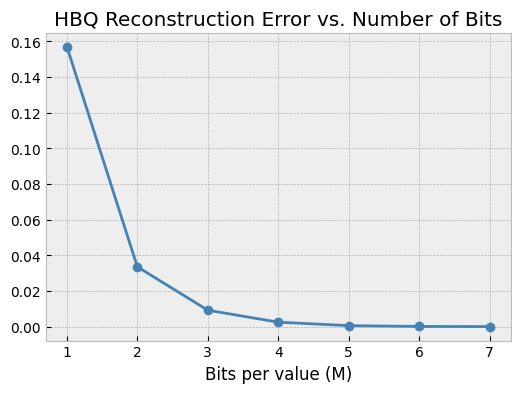

In [47]:
error = []
for i in range(1, 8):
    bits = hbq_encode(F_bounded, M=i)
    hbq_decoded = hbq_decode(bits)
    mse = torch.nn.functional.mse_loss(hbq_decoded, F_bounded).item()
    error.append(mse)
    print(f"M={i} bits → MSE: {mse:.6f}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, 8), error, marker="o", color="steelblue")
plt.title("HBQ Reconstruction Error vs. Number of Bits")
plt.xlabel("Bits per value (M)")

MSE halves with each additional bit, confirming the $\frac{1}{4} \cdot 2^{-M}$ bound. At $M = 6$ the reconstruction is already near machine precision for this 4×4 toy. For real 64×64 latents the curve looks identical — HBQ's error guarantee is resolution-independent.

## step-6 use VAE latents 

In [49]:
encode = hbq_encode(latents, M=4)
encode.shape

torch.Size([1, 4, 64, 64, 4])

torch.Size([1, 4, 64, 64])

## Where Is HBQ Used?

HBQ appears in **GRN (Generative Reconstruction Networks)** and similar tokenizer-free diffusion models that feed image latents to a transformer. Instead of learning a discrete codebook (VQVAE-style) and risking codebook collapse, HBQ converts $z \in (-1, 1)$ into a fixed-length binary sequence a language model can consume directly. The binary representation also enables *progressive refinement*: streaming $M$ bits per position is coarse-to-fine by construction — early bits set the rough structure, later bits fill in texture.